In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df=pd.read_csv("HousingData.csv")
valsy=df["RM"].to_numpy()
valsx=df["MEDV"].to_numpy()
print(valsy)
print(valsx)

[6.575 6.421 7.185 6.998 7.147 6.43  6.012 6.172 5.631 6.004 6.377 6.009
 5.889 5.949 6.096 5.834 5.935 5.99  5.456 5.727 5.57  5.965 6.142 5.813
 5.924 5.599 5.813 6.047 6.495 6.674 5.713 6.072 5.95  5.701 6.096 5.933
 5.841 5.85  5.966 6.595 7.024 6.77  6.169 6.211 6.069 5.682 5.786 6.03
 5.399 5.602 5.963 6.115 6.511 5.998 5.888 7.249 6.383 6.816 6.145 5.927
 5.741 5.966 6.456 6.762 7.104 6.29  5.787 5.878 5.594 5.885 6.417 5.961
 6.065 6.245 6.273 6.286 6.279 6.14  6.232 5.874 6.727 6.619 6.302 6.167
 6.389 6.63  6.015 6.121 7.007 7.079 6.417 6.405 6.442 6.211 6.249 6.625
 6.163 8.069 7.82  7.416 6.727 6.781 6.405 6.137 6.167 5.851 5.836 6.127
 6.474 6.229 6.195 6.715 5.913 6.092 6.254 5.928 6.176 6.021 5.872 5.731
 5.87  6.004 5.961 5.856 5.879 5.986 5.613 5.693 6.431 5.637 6.458 6.326
 6.372 5.822 5.757 6.335 5.942 6.454 5.857 6.151 6.174 5.019 5.403 5.468
 4.903 6.13  5.628 4.926 5.186 5.597 6.122 5.404 5.012 5.709 6.129 6.152
 5.272 6.943 6.066 6.51  6.25  7.489 7.802 8.375 5.8

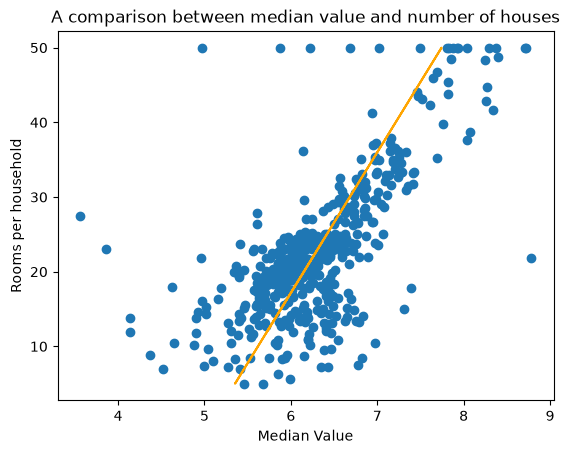

[0.05312235 5.08763867]


In [25]:
#normal equation
def MSE(tvals,pvals):
    loss=(pvals-tvals)**2
    cost=(loss.sum())/(loss.count())
    return cost

X=np.column_stack([valsx,np.ones(len(valsx))])
w=(np.linalg.inv(X.T.dot(X))).dot((X.T).dot(valsy))

regline=valsx*w[0]+w[1]
plt.scatter(valsy,valsx)
plt.plot(regline,valsx,color="orange")
plt.title("A comparison between median value and number of houses")
plt.xlabel("Median Value")
plt.ylabel("Rooms per household")
plt.show()
print(w)

In [26]:
error=regline-valsy
eperc=(np.mean(np.abs(error))/np.mean(valsy))*100
acc=100-eperc
print("Accuracy: ",acc)
print("Error",eperc)
print(error)

Accuracy:  94.43110092877797
Error 5.56889907122204
[-2.12424831e-01 -1.85918480e-01 -2.54015642e-01 -1.36074703e-01
 -1.36332111e-01  1.82250233e-01  2.92140580e-01  3.55254467e-01
  3.33157514e-01  8.76511636e-02 -4.92526017e-01  8.26511636e-02
  3.51393755e-01  2.22334695e-01 -4.15344843e-02  3.10773518e-01
  3.79765051e-01  2.72798679e-02  7.04710224e-01  3.27465516e-01
  2.40102687e-01  1.63836811e-01 -2.46901546e-01  4.49128057e-02
 -7.65260483e-03  2.27039393e-01  1.56469749e-01 -1.73150488e-01
 -4.29910013e-01 -4.70791893e-01  4.92925684e-02 -2.14087194e-01
 -1.61146255e-01  8.25415100e-02 -2.91209548e-01  1.58651164e-01
  3.09085753e-01  3.53208107e-01  4.33760817e-01  1.28807177e-01
 -8.23911715e-02 -2.69306710e-01  2.62634230e-01  1.88760817e-01
  1.44832578e-01  4.30900105e-01  3.64085753e-01 -6.05302508e-02
  4.53600570e-01  5.16212341e-01  1.71149047e-01  6.16469301e-02
 -9.53024767e-02  3.32701757e-01  2.03651164e-01 -2.80829994e-01
  1.67608171e-02 -4.96949399e-02  1.80

In [73]:
#gradient descent 
weight=np.random.rand(2)
print(weight)

#optimum learning weight
def calcgrad(weight):
    grad=(2/len(X))*(X.T).dot(X.dot(weight)-valsy)
    return grad


def GD(weight,n):
    for i in range(10000):
        weight=weight-n*calcgrad(weight)
    return weight

#bruhj
weightr=GD(weight,0.001)
print(weightr)



[0.95794985 0.30401841]
[0.06374036 4.80867186]


In [75]:
#lasso
def l1grad(weight):
    grad=(2/len(X))*(X.T).dot(X.dot(weight)-valsy)+2*weight
    return grad

def GD(weight,n):
    for i in range(10000):
        weight=weight-n*l1grad(weight)
    return weight

weightl=GD(weight,0.001)
print(weightl)

[0.22190837 0.64220802]


In [76]:
rline=valsx*weightr[0]+weightr[1]
l2line=valsx*weightl[0]+weightl[1]

def calcerr(rline):
    err=rline-valsy
    eper=(np.mean(np.abs(err))/np.mean(valsy))*100
    ac=100-eper
    print("Accuracy: ",ac)
    print("Error",eper)

calcerr(rline)
calcerr(l2line)


Accuracy:  94.4946317612979
Error 5.505368238702102
Accuracy:  78.30452509319339
Error 21.69547490680661


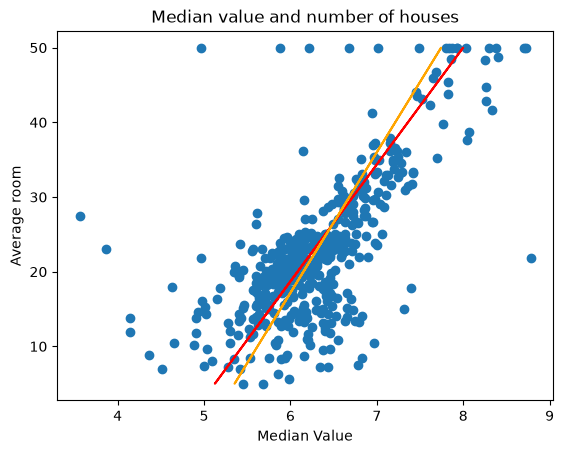

In [31]:
plt.scatter(valsy,valsx)
plt.plot(rline,valsx,color="red")
plt.plot(regline,valsx,color="orange")
plt.xlabel("Median Value")
plt.ylabel("Average room")
plt.title("Median value and number of houses")
plt.show()